# Figure 1 — CIFAR-10 generalization reproduction

Reads **existing experiment CSV/JSON results** and renders Figure 1(a), 1(b), and 1(c) **directly in the notebook**. No training or image/PDF files are created. Save the notebook to retain the displayed plots in its cell outputs. Missing runs are reported, never fabricated.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set manually if your results are elsewhere, e.g. Path(r"C:\...\results\figure1")
RESULTS_ROOT = None

def find_results():
    if RESULTS_ROOT is not None:
        root = Path(RESULTS_ROOT).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"Results directory not found: {root}")
        return root
    cwd = Path.cwd().resolve()
    candidates = [cwd / 'results' / 'figure1', cwd.parent / 'results' / 'figure1', cwd / 'paper1-generalization' / 'results' / 'figure1']
    for root in candidates:
        if root.is_dir():
            return root
    raise FileNotFoundError('Cannot find results/figure1. Set RESULTS_ROOT in this cell to your absolute results folder.')

root = find_results()
print('Reading:', root)

Reading: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper1-generalization\results\figure1


## Figure 1(a): Inception learning curves

Plots recorded **minibatch cross-entropy** against optimization steps, with a trailing moving average for readability. All plotted points are measured data; no extrapolation. Missing curves are omitted.

True labels: 25,000 logged steps; last step 25,000
Random labels: 25,000 logged steps; last step 25,000
Shuffled pixels: 25,000 logged steps; last step 25,000
Random pixels: 25,000 logged steps; last step 25,000
Gaussian: 25,000 logged steps; last step 25,000


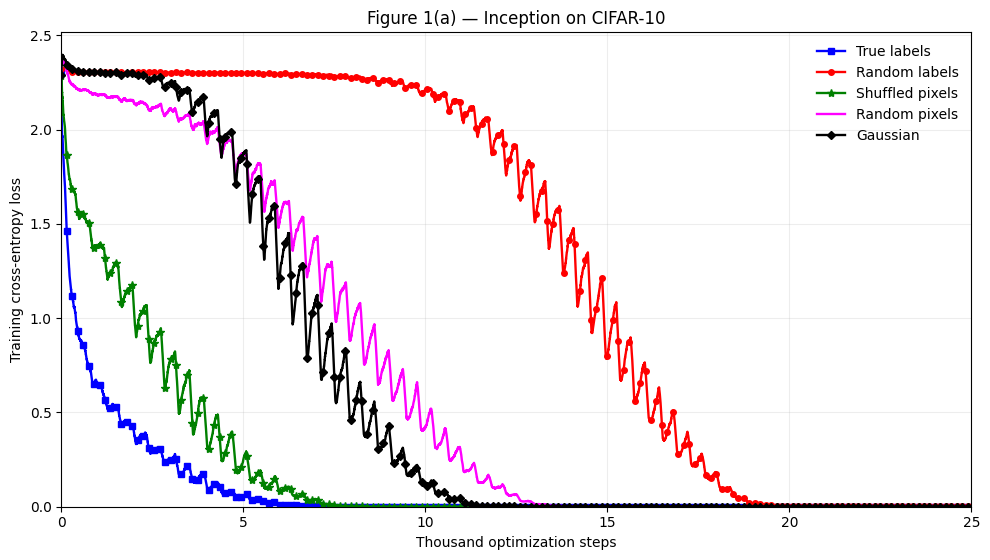

Displayed Figure 1(a), 5/5 curves


In [4]:
CONDITIONS = [
    # Label, CSV path, original paper color, original paper marker
    ('True labels', 'label_corruption/inception/p000/steps.csv', 'blue', 's'),
    ('Random labels', 'label_corruption/inception/p100/steps.csv', 'red', 'o'),
    ('Shuffled pixels', 'input_randomization/inception/shared_shuffle/steps.csv', 'green', '*'),
    ('Random pixels', 'input_randomization/inception/independent_shuffle/steps.csv', 'magenta', None),
    ('Gaussian', 'input_randomization/inception/gaussian/steps.csv', 'black', 'D'),
]

MAX_STEPS = 25_000
SMOOTHING_STEPS = 100  # 1 = raw minibatch loss

def trailing_mean(values, window):
    if window <= 1:
        return values.copy()
    return pd.Series(values).rolling(
        window, min_periods=1
    ).mean().to_numpy()

fig, ax = plt.subplots(figsize=(10, 5.7))
count = 0

for label, relative_path, color, marker in CONDITIONS:
    f = root / relative_path

    if not f.is_file():
        print('MISSING:', label, '→', relative_path)
        continue

    d = pd.read_csv(f, usecols=['step', 'batch_train_ce'])
    d = d[
        (d.step <= MAX_STEPS) &
        np.isfinite(d.batch_train_ce)
    ].sort_values('step')

    d = d.drop_duplicates('step', keep='last')

    if d.empty:
        print('EMPTY:', label, '→', relative_path)
        continue

    ax.plot(
        d.step / 1000,
        trailing_mean(d.batch_train_ce.to_numpy(), SMOOTHING_STEPS),
        label=label,
        color=color,
        linewidth=1.7,
        marker=marker,
        markersize=4 if marker != '*' else 6,
        markevery=150 if marker else None,
    )

    print(f'{label}: {len(d):,} logged steps; last step {d.step.iloc[-1]:,}')
    count += 1

if count == 0:
    plt.close(fig)
    raise ValueError('No Inception steps.csv files found.')

ax.set(
    xlabel='Thousand optimization steps',
    ylabel='Training cross-entropy loss',
    title='Figure 1(a) — Inception on CIFAR-10'
)

ax.set_xlim(0, MAX_STEPS / 1000)
ax.set_ylim(bottom=0)
ax.grid(alpha=0.22)
ax.legend(frameon=False)

fig.tight_layout()
display(fig)
plt.close(fig)

print(f'Displayed Figure 1(a), {count}/5 curves')

## Figures 1(b) and 1(c): Label corruption

Uses the configured subset of corruption levels (`0`, `0.2`, `0.6`, `1.0`) across MLP, AlexNet, and Inception.

- **1(b):** convergence detection steps relative to that architecture's `p=0` baseline. Missing convergence is **not** treated as the final training step.
- **1(c):** test classification error at the first recorded convergence evaluation, when available; otherwise at the final recorded epoch, explicitly marked as a nonconverged endpoint.

The exact stopping rule used by the trainer is *training error ≤0.1% for two consecutive evaluations*. Experiments not satisfying it will be absent from 1(b).

In [ ]:
MODELS = [('mlp', 'MLP'), ('alexnet', 'AlexNet'), ('inception', 'Inception')]
PROBABILITIES = [0.0, 0.2, 0.6, 1.0]

records = []
for model, model_label in MODELS:
    for p in PROBABILITIES:
        folder = root / 'label_corruption' / model / f'p{round(p*100):03d}'
        meta_file, ep_file = folder / 'metadata.json', folder / 'epochs.csv'
        if not meta_file.is_file() or not ep_file.is_file():
            print(f'MISSING: {model_label} at p={p:g} ({folder})')
            continue
        try:
            meta = json.loads(meta_file.read_text(encoding='utf-8'))
            epochs = pd.read_csv(ep_file).sort_values('step').drop_duplicates('step', keep='last')
            if epochs.empty: raise ValueError('empty epochs.csv')
            converged_step = meta.get('convergence_step')
            if converged_step in ('', None):
                converged_step = None
            else:
                converged_step = int(converged_step)
            # Test error at the convergence evaluation, not automatically at the last epoch.
            candidate = epochs.loc[epochs.step == converged_step] if converged_step is not None else epochs.iloc[0:0]
            endpoint = candidate.iloc[0] if not candidate.empty else epochs.iloc[-1]
            records.append(dict(model=model, label=model_label, p=p,
                convergence_step=converged_step,
                test_error_pct=float(endpoint.test_error)*100,
                train_error_pct=float(endpoint.train_error)*100,
                test_measurement='at convergence' if not candidate.empty else 'last available epoch',
                final_logged_step=int(epochs.step.iloc[-1])))
        except Exception as exc:
            print(f'INVALID: {folder}: {exc}')

df = pd.DataFrame(records)
if not df.empty:
    display(df.sort_values(['model', 'p']).reset_index(drop=True))
else:
    print('No complete label-corruption runs found yet.')

In [ ]:
if df.empty:
    print('Figure 1(b) unavailable: no label-corruption runs.')
else:
    fig, ax = plt.subplots(figsize=(8.5, 5.3))
    plotted = 0
    for model, label in MODELS:
        subset = df[df.model == model].set_index('p')
        baseline = subset.loc[0.0, 'convergence_step'] if 0.0 in subset.index else None
        if baseline is None or pd.isna(baseline) or float(baseline) <= 0:
            print(f'Figure 1(b): {label} has no converged p=0 baseline; omitted.')
            continue
        valid = subset.dropna(subset=['convergence_step']).sort_index()
        if valid.empty: continue
        ax.plot(valid.index.to_numpy(), valid.convergence_step.to_numpy() / float(baseline), 'o-', linewidth=1.8, label=label)
        plotted += 1
    if plotted:
        ax.set(xlabel='Fraction of corrupted labels', ylabel='Relative convergence steps (p=0 → 1)',
               title='Figure 1(b) — Relative convergence time')
        ax.set_xticks(PROBABILITIES)
        ax.grid(alpha=.22)
        ax.legend(frameon=False)
        fig.tight_layout()
        display(fig)
        print(f'Displayed Figure 1(b), {plotted}/3 architecture curves')
    else:
        print('Figure 1(b) unavailable: no architecture has a converged p=0 baseline.')
    plt.close(fig)

In [ ]:
if df.empty:
    print('Figure 1(c) unavailable: no label-corruption runs.')
else:
    fig, ax = plt.subplots(figsize=(8.5, 5.3))
    plotted = 0
    for model, label in MODELS:
        subset = df[df.model == model].sort_values('p')
        if subset.empty: continue
        at_convergence = subset.test_measurement.eq('at convergence')
        ax.plot(subset.p, subset.test_error_pct, '-', linewidth=1.8, label=label)
        ax.scatter(subset.loc[at_convergence, 'p'], subset.loc[at_convergence, 'test_error_pct'], marker='o', s=45)
        ax.scatter(subset.loc[~at_convergence, 'p'], subset.loc[~at_convergence, 'test_error_pct'], marker='x', s=65)
        plotted += 1
    ax.set(xlabel='Fraction of corrupted labels', ylabel='Test classification error (%)',
           title='Figure 1(c) — Generalization under label corruption')
    ax.set_xticks(PROBABILITIES)
    ax.set_ylim(0, 100)
    ax.grid(alpha=.22)
    ax.legend(frameon=False, title='○ converged  × budget-limited')
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    print(f'Displayed Figure 1(c), {plotted}/3 architecture curves')
    print('× points are test errors at the final available epoch, NOT at convergence.')